# 01 — Explorer et contrôler le corpus

**Objectif :** comprendre ce qui est disponible avant toute conclusion thématique.
Le corpus actuel est un pilote de septembre 2015 ; il ne représente pas tout le pontificat.

Exécuter les cellules dans l'ordre avec le noyau Python du projet. Installation : `pip install -r requirements.txt` depuis la racine. Aucun téléchargement n'est déclenché par ce notebook.

In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "telecharger_discours.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dossier du projet.")
CORPUS = ROOT / "corpus_francois" / "corpus_nlp.jsonl"
if not CORPUS.exists():
    raise FileNotFoundError("Exécuter telecharger_discours.py puis preparer_corpus.py ; voir README.")
LANGUE = "fr"
df_all = pd.read_json(CORPUS, lines=True)
df = df_all.loc[df_all["language"].eq(LANGUE)].copy()
if df.empty:
    raise ValueError(f"Aucun document en {LANGUE}.")
if df.duplicated(["event_id", "language"]).any():
    raise ValueError("Doublons événement/langue : examiner le corpus avant l'analyse.")
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["text"] = df["text"].fillna("")
df["venue_raw"] = df["venue_raw"].fillna("")
df["n_mots"] = df["text"].str.findall(r"\b[^\W\d_]+(?:[’'-][^\W\d_]+)*\b").str.len()
RESULTATS = ROOT / "resultats"
RESULTATS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 14})
print(f"{len(df)} versions {LANGUE} ; {df['event_id'].nunique()} documents distincts.")
print("Période :", df["date"].min(), "→", df["date"].max())


Matplotlib is building the font cache; this may take a moment.


33 versions fr ; 33 documents distincts.
Période : 2015-09-03 00:00:00 → 2015-09-27 00:00:00


## Couverture et qualité

Une traduction est une version du même document. Le tableau de couverture décrit les fichiers collectés, pas les langues réellement prononcées ni les traductions manquantes sur le site.

In [2]:
display(pd.crosstab(df_all["pope"], df_all["language"]))
qualite = pd.Series({
    "documents": len(df),
    "dates manquantes": df["date"].isna().sum(),
    "textes vides": df["text"].str.strip().eq("").sum(),
    "lieux inconnus": df["venue_raw"].eq("").sum(),
    "textes identiques (après le premier)": df["text"].duplicated().sum(),
    "caractères de remplacement": df["text"].str.count("\ufffd").sum(),
    "moins de 100 mots (à examiner)": df["n_mots"].lt(100).sum(),
}, name="nombre")
display(qualite.to_frame())
display(df.groupby("cleaning_status").size().rename("documents").to_frame())
display(df[["date", "title", "venue_raw", "n_mots"]].sort_values("n_mots").head(8))
qualite.to_csv(RESULTATS / "qualite_corpus.csv", encoding="utf-8-sig")

language,fr
pope,
francesco,33


,nombre
documents,33
dates manquantes,0
textes vides,0
lieux inconnus,3
textes identiques (après le premier),0
caractères de remplacement,0
moins de 100 mots (à examiner),0


,documents
cleaning_status,
initial_centered_header_removed,33


,date,title,venue_raw,n_mots
14,2015-09-19,"Voyage apostolique à Cuba, aux États-Unis et à...",,228
22,2015-09-25,Voyage apostolique - ONU : Salut au personnel ...,New York,411
8,2015-09-16,Aux ministres de l'environnement des États mem...,Salon adjacent à la salle Paul VI,502
32,2015-09-27,Voyage apostolique - États-Unis d'Amérique : R...,"Séminaire Saint-Charles Borromée, Philadelphie",525
28,2015-09-27,Voyage apostolique - États-Unis d'Amérique : S...,Aéroport international de Philadelphie,665
18,2015-09-23,Voyage apostolique - États-Unis d'Amérique : C...,"South Lawn de la Maison Blanche, Washington, D.C.",666
12,2015-09-18,Aux participants au Symposium organisé par l'O...,Salle des Papes,674
1,2015-09-05,Aux membres des cellules paroissiales d'évangé...,Salle Paul VI,754


## Répartition temporelle et longueur

Les pics peuvent refléter un voyage ou la couverture de collecte. Sur un mois unique, aucune tendance de pontificat n'est estimable.

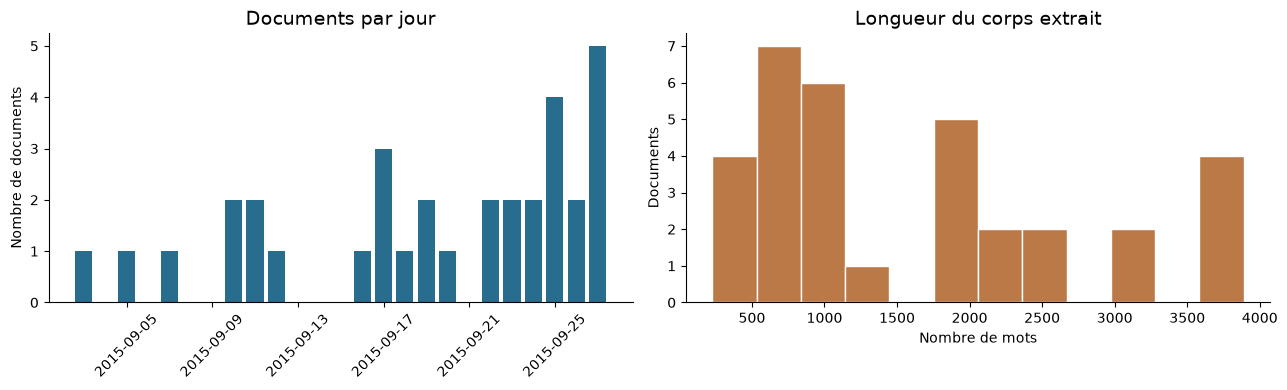

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
par_jour = df.dropna(subset=["date"]).groupby("date").size()
if len(par_jour):
    axes[0].bar(par_jour.index, par_jour.values, color="#286c8e")
    axes[0].tick_params(axis="x", rotation=45)
axes[0].set(title="Documents par jour", ylabel="Nombre de documents")
axes[1].hist(df["n_mots"], bins=min(12, len(df)), color="#bb7947", edgecolor="white")
axes[1].set(title="Longueur du corps extrait", xlabel="Nombre de mots", ylabel="Documents")
fig.tight_layout()
fig.savefig(RESULTATS / "couverture_longueurs.png", dpi=160, bbox_inches="tight")
plt.show()

## Lire un texte et chercher un mot en contexte

Changer `REQUETE` pour lire les passages derrière un résultat. Les notes, citations et questions des journalistes peuvent rester dans le corps : vérifier les textes concernés avant interprétation.

In [4]:
REQUETE = "paix"
motif = re.compile(r"\b" + re.escape(REQUETE) + r"\b", re.I)
extraits = []
for row in df.itertuples():
    for match in list(motif.finditer(row.text))[:3]:
        extraits.append({"date": row.date, "titre": row.title,
                         "contexte": row.text[max(0, match.start()-100):match.end()+150],
                         "source": row.source_url})
display(pd.DataFrame(extraits).head(20))
print(f"{sum(bool(motif.search(t)) for t in df['text'])}/{len(df)} documents contiennent {REQUETE!r}.")

,date,titre,contexte,source
0,2015-09-07,Aux prélats de la Conférence épiscopale du Por...,it pas toujours suivie. Le peuple portugais es...,https://www.vatican.va/content/francesco/fr/sp...
1,2015-09-10,Aux nouveaux évêques nommés au cours de l'anné...,"Très chers frères dans l’épiscopat, la paix so...",https://www.vatican.va/content/francesco/fr/sp...
2,2015-09-10,Aux nouveaux évêques nommés au cours de l'anné...,visage du Ressuscité recompose les fragments ...,https://www.vatican.va/content/francesco/fr/sp...
3,2015-09-17,Aux participants à la rencontre sur la crise h...,ragiques de cette crise. En communion avec vou...,https://www.vatican.va/content/francesco/fr/sp...
4,2015-09-17,Audience aux jeunes consacrés (17 septembre 2015),du désert écrivent à propos de cela et nous e...,https://www.vatican.va/content/francesco/fr/sp...
5,2015-09-17,Liaison télévisée retransmise par la CNN avec ...,ion est un droit humain.\n\nLa question suivan...,https://www.vatican.va/content/francesco/fr/sp...
6,2015-09-17,Liaison télévisée retransmise par la CNN avec ...,il a béni symboliquement un olivier dans la t...,https://www.vatican.va/content/francesco/fr/sp...
7,2015-09-18,Aux participants au Symposium organisé par l'O...,"qui maintient en existence tout l’univers, pa...",https://www.vatican.va/content/francesco/fr/sp...
8,2015-09-19,Voyage apostolique - Cuba : Cérémonie de bienv...,r tous ses fils cubains et pour cette chère Na...,https://www.vatican.va/content/francesco/fr/sp...
9,2015-09-19,Voyage apostolique - Cuba : Cérémonie de bienv...,"outes vos potentialités, comme preuve du haut ...",https://www.vatican.va/content/francesco/fr/sp...


22/33 documents contiennent 'paix'.


## Inspection du nettoyage

Comparer l'en-tête retiré et le début du corps ; modifier `POSITION` pour examiner un autre document.

In [5]:
POSITION = 0
row = df.sort_values(["date", "event_id"]).iloc[POSITION]
print(row["title"], "\n", row["source_url"])
print("\nEN-TÊTE :\n", row["header"])
print("\nCORPS (début) :\n", row["text"][:2200])
df.drop(columns=["text", "header"]).to_csv(RESULTATS / "inventaire_analyse.csv", index=False, encoding="utf-8-sig")

Aux participants au chapitre général des prêtres de Schönstatt (3 septembre 2015) 
 https://www.vatican.va/content/francesco/fr/speeches/2015/september/documents/papa-francesco_20150903_sacerdoti-schonstatt.html

EN-TÊTE :
 DISCOURS DU PAPE FRANÇOIS AUX PARTICIPANTS AU CHAPITRE GÉNÉRAL DES PRÊTRES DE SCHÖNSTATT
Salle du Consistoire Jeudi 3 septembre 2015
[ Multimédia ]

CORPS (début) :
 Chers frères prêtres,

Je suis heureux d’être avec vous en cette rencontre. Je remercie Juan Pablo pour ses paroles, de même que pour son témoignage d’affection au nom des membres du Mouvement. Je conserve encore un vif souvenir de la rencontre de l’an dernier.

Le ve chapitre général que vous venez de célébrer a eu lieu pour le 50e anniversaire de la fondation de l’institut par le père Josef Kentenich. Et après ces années de chemin, vous avez à cœur de maintenir vivant le charisme fondateur et la capacité de savoir le transmettre aux plus jeunes. Il m’importe aussi qu’ils le maintiennent et le transmet

## Avant de poursuivre

- Vérifier les textes très courts, les en-têtes atypiques et les entretiens à plusieurs locuteurs.
- Examiner l'équilibre par période et langue quand le corpus sera étendu.
- Passer au notebook 02 pour annoter les lieux, puis au 03 pour les thèmes.